# Assignment 5 - S2 Low-Volatility Minimum-Variance Core

Liquid Swiss equities, low trailing volatility screen, long-only minimum-variance weights.

## 1. Imports and Paths

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from estimation.covariance import Covariance
from optimization.optimization import MinVariance
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)
from backtesting.backtest_item_builder.bibfn_constraints import (
    bibfn_budget_constraint,
    bibfn_box_constraints,
)

## 2. Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Parameters

In [4]:
N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
VOL_LOOKBACK_DAYS = 252 * 2
LOW_VOL_PERCENTILE = 0.40
COVARIANCE_LOOKBACK_DAYS = 252 * 3

MAX_STOCK_WEIGHT = 0.10
MAX_SECTOR_WEIGHT = 0.45

print('Low-volatility percentile:', LOW_VOL_PERCENTILE)
print('Max stock weight:', MAX_STOCK_WEIGHT)

Low-volatility percentile: 0.4
Max stock weight: 0.1


## 4. Builder Functions

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    width = kwargs.get('width', RETURN_HISTORY_DAYS)
    min_obs = kwargs.get('min_obs', MIN_RETURN_OBS)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= min_obs).astype(int),
    })


def bibfn_selection_low_volatility(bs, rebdate, **kwargs):
    width = kwargs.get('width', VOL_LOOKBACK_DAYS)
    low_vol_percentile = kwargs.get('low_vol_percentile', LOW_VOL_PERCENTILE)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(low_vol_percentile)

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def bibfn_sector_caps(bs, rebdate, **kwargs):
    max_sector_weight = kwargs.get('max_sector_weight', MAX_SECTOR_WEIGHT)
    ids = bs.optimization.constraints.ids
    if len(ids) == 0 or 'sector' not in bs.data.market_data.columns:
        return None

    market_dates = bs.data.market_data.index.get_level_values('date')
    sectors = (
        bs.data.market_data.loc[market_dates <= pd.to_datetime(rebdate), 'sector']
        .groupby(level='id')
        .last()
        .reindex(ids)
        .fillna('Unknown')
    )

    rows = []
    names = []
    for sector_name, sector_ids in sectors.groupby(sectors).groups.items():
        row = pd.Series(0.0, index=ids)
        row.loc[list(sector_ids)] = 1.0
        rows.append(row)
        names.append(f'sector_{sector_name}')

    if rows:
        G = pd.DataFrame(rows, index=names)
        sense = pd.Series('<=', index=G.index)
        rhs = pd.Series(max_sector_weight, index=G.index)
        bs.optimization.constraints.add_linear(G=G, sense=sense, rhs=rhs)

    return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing Dates

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'low_volatility': SelectionItemBuilder(
        bibfn=bibfn_selection_low_volatility,
        width=VOL_LOOKBACK_DAYS,
        low_vol_percentile=LOW_VOL_PERCENTILE,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=COVARIANCE_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
    'budget': OptimizationItemBuilder(
        bibfn=bibfn_budget_constraint,
        budget=1,
    ),
    'box': OptimizationItemBuilder(
        bibfn=bibfn_box_constraints,
        box_type='LongOnly',
        lower=0,
        upper=MAX_STOCK_WEIGHT,
    ),
    'sector_caps': OptimizationItemBuilder(
        bibfn=bibfn_sector_caps,
        max_sector_weight=MAX_SECTOR_WEIGHT,
    ),
}

optimization = MinVariance(
    covariance=Covariance(method='pearson', check_positive_definite=True),
    solver_name='osqp',
)

bs_s2 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s2 = Backtest()
bt_s2.run(bs=bs_s2)

weights_s2 = bt_s2.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s2.shape)
print('Average holdings:', weights_s2.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s2.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (85, 116)
Average holdings: 34.6
Average max stock weight: 0.059


## 7. Returns

In [8]:
return_series = data.get_return_series(weekdays_only=False)

s2_gross_returns = bt_s2.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
s2_gross_returns.name = 'S2 gross'

s2_net_returns = bt_s2.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s2_net_returns.name = 'S2 net'

comparison = pd.concat(
    {
        'S2 net': s2_net_returns,
        'S2 gross': s2_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)

2003-02-03 to 2024-04-30
           count      mean       std       min       25%       50%       75%  \
S2 net    5609.0  0.000278  0.006922 -0.073774 -0.002558  0.000396  0.003830   
S2 gross  5609.0  0.000340  0.006923 -0.073735 -0.002490  0.000440  0.003884   
SPI       5609.0  0.000332  0.009932 -0.091109 -0.004052  0.000350  0.005263   

               max  
S2 net    0.060767  
S2 gross  0.060885  
SPI       0.105788  


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


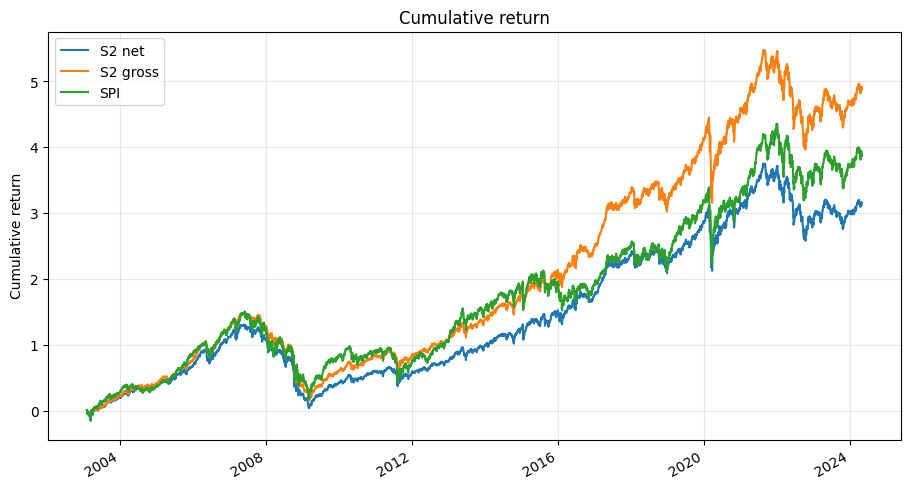

In [9]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Cumulative return')
ax.grid(alpha=0.3)
plt.show()

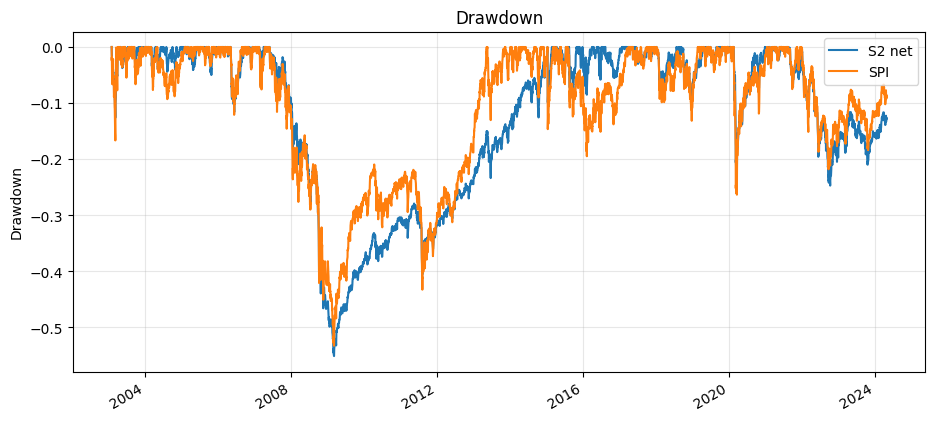

In [10]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    return wealth / wealth.cummax() - 1


ax = drawdown(comparison[['S2 net', 'SPI']]).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
ax.grid(alpha=0.3)
plt.show()

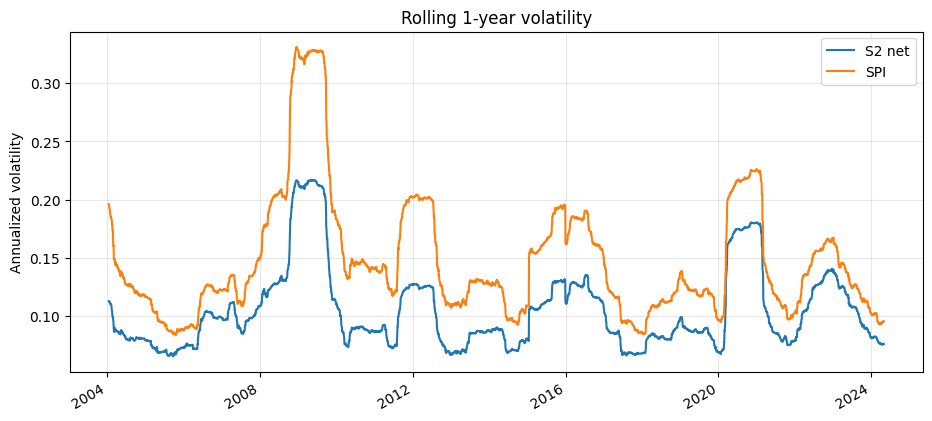

In [11]:
rolling_1y_vol = comparison.rolling(252).std() * np.sqrt(252)
ax = rolling_1y_vol[['S2 net', 'SPI']].plot(figsize=(11, 5), title='Rolling 1-year volatility')
ax.set_ylabel('Annualized volatility')
ax.grid(alpha=0.3)
plt.show()

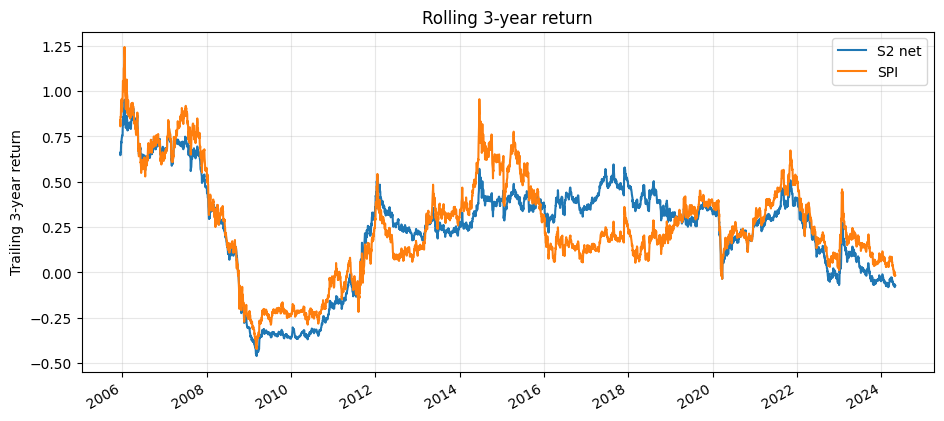

In [12]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return[['S2 net', 'SPI']].plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Trailing 3-year return')
ax.grid(alpha=0.3)
plt.show()

## 8. Statistics

In [13]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

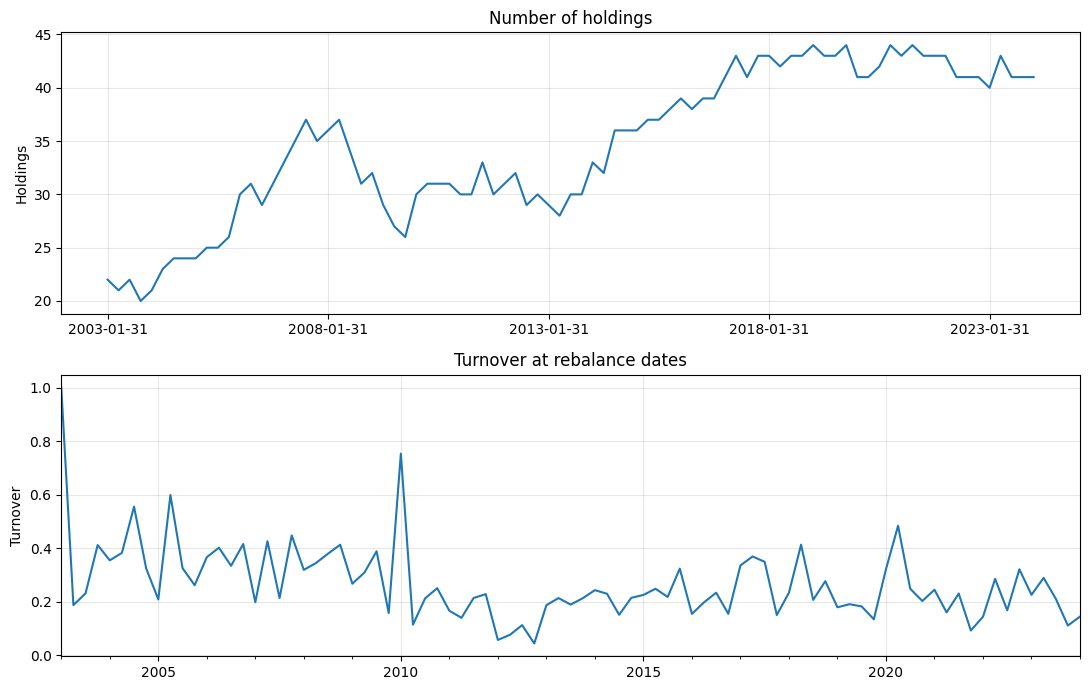

Average turnover: 0.269
Median turnover: 0.231


In [14]:
turnover_s2 = bt_s2.strategy.turnover(return_series=return_series, rescale=False)
turnover_s2.index = pd.to_datetime(turnover_s2.index)
turnover_s2.name = 'turnover'

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
weights_s2.gt(0).sum(axis=1).plot(ax=axes[0], title='Number of holdings')
axes[0].set_ylabel('Holdings')
axes[0].grid(alpha=0.3)
turnover_s2.plot(ax=axes[1], title='Turnover at rebalance dates')
axes[1].set_ylabel('Turnover')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Average turnover:', turnover_s2.mean().round(3))
print('Median turnover:', turnover_s2.median().round(3))

## 9. Selection Diagnostics

In [15]:
selection_counts = []
for rebdate in rebdates:
    bs_s2.build_selection(rebdate)
    binary = bs_s2.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

,return_history,gaps,min_volume,low_volatility,selected_after_all_filters
2023-01-31,110.0,110.0,110.0,44.0,44.0
2023-04-30,108.0,108.0,108.0,43.0,43.0
2023-07-31,103.0,103.0,103.0,41.0,41.0
2023-10-31,102.0,102.0,102.0,41.0,41.0
2024-01-31,102.0,102.0,102.0,41.0,41.0


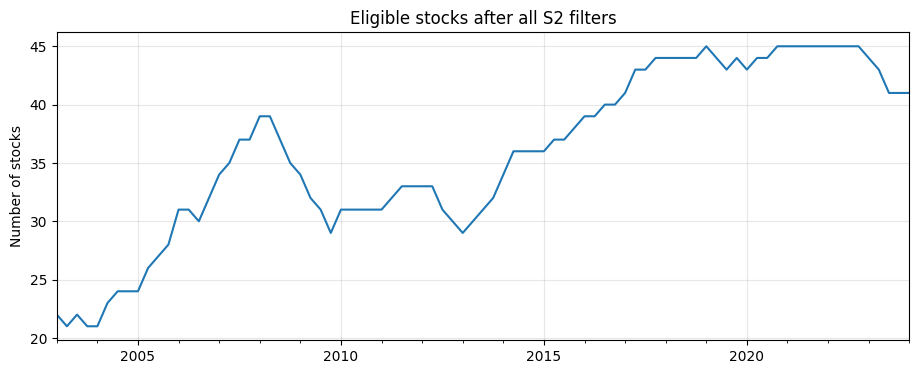

,count,mean,std,min,25%,50%,75%,max
return_history,85.0,89.000000,18.159348,51.0,76.0,89.0,108.0,113.0
gaps,85.0,89.000000,18.159348,51.0,76.0,89.0,108.0,113.0
min_volume,85.0,89.000000,18.159348,51.0,76.0,89.0,108.0,113.0
low_volatility,85.0,35.823529,7.198175,21.0,31.0,36.0,43.0,45.0
selected_after_all_filters,85.0,35.823529,7.198175,21.0,31.0,36.0,43.0,45.0


In [16]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Eligible stocks after all S2 filters',
)
ax.set_ylabel('Number of stocks')
ax.grid(alpha=0.3)
plt.show()

selection_counts.describe().T

## 10. Summary

S2 is a low-volatility equity core. It screens for liquid stocks with enough return history, keeps the lower-volatility part of the universe, and uses minimum-variance weights with concentration controls.